# Analisando Grafos do SNAP: web-flickr (G114)

In [1]:
from src.config import SEED, DATA_RAW

## Leitura do grafo

Uma vista rápida da lista de arestas bruta baixada do SNAP em `data/raw/`, ainda sem nenhum tratamento: contagens, graus e a vizinhança de um vértice.

In [2]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from src.io import read_edge_list

### Contagens brutas

O arquivo comprimido é lido em fluxo, sem o cabeçalho. O grau bruto de um vértice é o número de linhas em que ele aparece.

In [3]:
raw_edges = read_edge_list(DATA_RAW / "flickrEdges.txt.gz")
edge_array = np.array(raw_edges, dtype=np.int64)
vertex_ids, raw_degrees = np.unique(edge_array, return_counts=True)
pd.Series({"linhas de arestas": len(raw_edges), "vértices distintos": len(vertex_ids)})

linhas de arestas     2316948
vértices distintos     105938
dtype: int64

### Histograma dos graus brutos

O eixo vertical está em escala log para que as faixas de grau alto, com poucos vértices, fiquem visíveis.

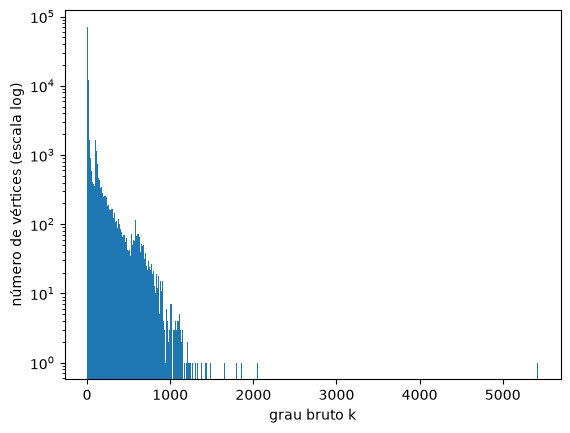

In [4]:
figure, axes = plt.subplots()
axes.hist(raw_degrees, bins="auto")
axes.set_yscale("log")
axes.set_xlabel("grau bruto k")
axes.set_ylabel("número de vértices (escala log)")
plt.show()

### Vizinhança de um vértice

Um vértice é sorteado com a semente `SEED`, e o subgrafo induzido por ele e pelos seus vizinhos é filtrado da lista de arestas, sem montar o grafo inteiro em memória no networkx.

In [5]:
rng = np.random.default_rng(SEED)
center_vertex = int(rng.choice(vertex_ids))

touches_center = (edge_array[:, 0] == center_vertex) | (edge_array[:, 1] == center_vertex)
neighborhood_vertices = np.unique(edge_array[touches_center])
has_both_ends_in_neighborhood = np.isin(edge_array, neighborhood_vertices).all(axis=1)
neighborhood_graph = nx.Graph(edge_array[has_both_ends_in_neighborhood].tolist())

pd.Series(
    {
        "vértice sorteado": center_vertex,
        "vértices na vizinhança": neighborhood_graph.number_of_nodes(),
        "arestas na vizinhança": neighborhood_graph.number_of_edges(),
    }
)

vértice sorteado          528275245
vértices na vizinhança          157
arestas na vizinhança          3750
dtype: int64

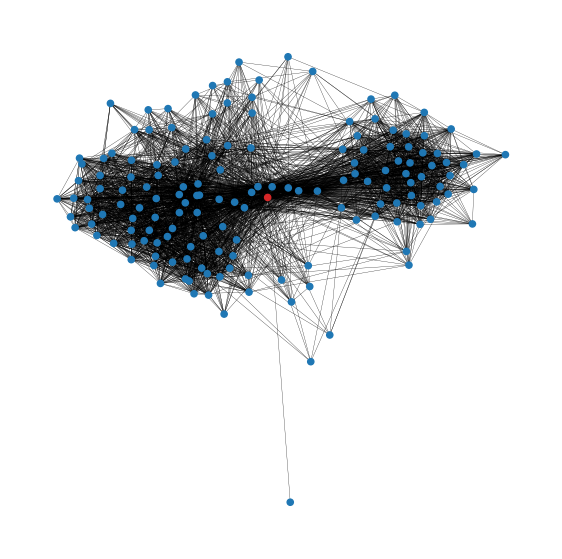

In [6]:
layout = nx.spring_layout(neighborhood_graph, seed=SEED)
vertex_colors = ["tab:red" if v == center_vertex else "tab:blue" for v in neighborhood_graph]

figure, axes = plt.subplots(figsize=(7, 7))
nx.draw_networkx(
    neighborhood_graph, layout, ax=axes, node_color=vertex_colors,
    node_size=20, width=0.2, with_labels=False,
)
axes.set_axis_off()
plt.show()

## Tratamento dos dados

A lista bruta vira um grafo simples não direcionado, com vértices de 0 a n − 1, e dele se extrai a maior componente conexa. Os dois conjuntos e o mapa de IDs vão para `data/processed/`.

In [7]:
import numpy as np
import pandas as pd

from src.config import DATA_RAW, DATA_PROCESSED, TABLES_DIR
from src.io import read_edge_list, write_edge_list
from src.tratamento import (
    extract_largest_component,
    reindex_vertices,
    remove_duplicate_edges,
    remove_self_loops,
)

### Grafo simples e maior componente

Cada par é uma aresta não ordenada. Os auto-laços e as arestas repetidas saem, e os vértices são renumerados na ordem do ID original. A maior componente recebe numeração própria.

In [8]:
raw_edges = np.array(read_edge_list(DATA_RAW / "flickrEdges.txt.gz"))
edges_without_self_loops = remove_self_loops(raw_edges)
deduplicated_edges = remove_duplicate_edges(edges_without_self_loops)
simple_edges, original_ids = reindex_vertices(deduplicated_edges)
lcc_edges, lcc_vertices = extract_largest_component(simple_edges, len(original_ids))

assert (simple_edges[:, 0] < simple_edges[:, 1]).all(), "o grafo simples tem auto-laços"
assert len(np.unique(simple_edges, axis=0)) == len(simple_edges), "o grafo simples tem arestas repetidas"

### Gravação

O mapa liga cada vértice ao ID original e ao índice na maior componente, vazio para quem está fora dela. A compressão grava sem data no cabeçalho, para que reexecutar não altere os arquivos versionados.

In [9]:
write_edge_list(simple_edges, DATA_PROCESSED / "flickr_simples.edgelist.gz")
write_edge_list(lcc_edges, DATA_PROCESSED / "flickr_lcc.edgelist.gz")

id_map = pd.DataFrame({"original_id": original_ids})
id_map["lcc_vertex"] = pd.Series(range(len(lcc_vertices)), index=lcc_vertices, dtype="Int64")
id_map.to_csv(
    DATA_PROCESSED / "mapa_ids.csv.gz",
    index_label="vertex",
    compression={"method": "gzip", "mtime": 0},
)

### Tabela antes × depois

In [10]:
treatment_table = pd.DataFrame(
    {
        "Lista bruta": [
            len(np.unique(raw_edges)),
            len(raw_edges),
            len(raw_edges) - len(edges_without_self_loops),
            len(edges_without_self_loops) - len(deduplicated_edges),
        ],
        "Grafo simples": [len(original_ids), len(simple_edges), 0, 0],
        "Maior componente": [len(lcc_vertices), len(lcc_edges), 0, 0],
    },
    index=["Vértices", "Arestas", "Auto-laços", "Arestas repetidas"],
)
treatment_table.style.format(thousands=".").to_latex(TABLES_DIR / "tratamento.tex", hrules=True)
treatment_table

,Lista bruta,Grafo simples,Maior componente
Vértices,105938,105938,105722
Arestas,2316948,2316948,2316668
Auto-laços,0,0,0
Arestas repetidas,0,0,0


## Medidas básicas e componentes

Número de vértices e de arestas, graus, densidade e componentes conexas do grafo simples completo, lido de `data/processed/`. Alimenta a subseção Parte I dos resultados do relatório.

In [11]:
import igraph as ig
import networkx as nx
import pandas as pd

from src.config import DATA_PROCESSED, TABLES_DIR
from src.io import read_edge_list

### Graus e densidade

O grau médio é a média dos graus de todos os vértices, conferida com 2m/n, e a densidade é 2m/(n(n − 1)), a fração dos pares de vértices ligados por aresta.

In [12]:
edges = read_edge_list(DATA_PROCESSED / "flickr_simples.edgelist.gz")
graph = nx.Graph(edges)
n, m = graph.number_of_nodes(), graph.number_of_edges()
degrees = pd.Series(dict(graph.degree()))

assert abs(degrees.mean() - 2 * m / n) < 1e-9, "o grau médio difere de 2m/n"

### Componentes conexas

O tamanho de cada componente vem do networkx, e o número de componentes é conferido com o igraph, uma segunda implementação.

In [13]:
component_sizes = pd.Series([len(component) for component in nx.connected_components(graph)])
igraph_components = ig.Graph(n=n, edges=edges).connected_components()

assert component_sizes.sum() == n, "a soma dos tamanhos das componentes difere de n"
assert len(component_sizes) == len(igraph_components), "networkx e igraph contam componentes diferentes"

### Tabelas

A tabela de medidas básicas reúne os valores acima. Na tabela de componentes, cada linha é um tamanho com o número de componentes que o têm: a maior componente fica sozinha na primeira linha, e as pequenas ficam agrupadas por tamanho.

In [14]:
basic_measures = pd.Series(
    {
        "Vértices ($n$)": n,
        "Arestas ($m$)": m,
        "Grau mínimo": degrees.min(),
        "Grau máximo": degrees.max(),
        "Grau médio": degrees.mean(),
        "Densidade": 2 * m / (n * (n - 1)),
        "Componentes conexas": len(component_sizes),
    },
    dtype=object,
).to_frame("Valor")
basic_measures.style.format(thousands=".", decimal=",", precision=6).to_latex(
    TABLES_DIR / "basicas.tex", hrules=True, column_format="lr"
)
basic_measures

,Valor
Vértices ($n$),105938
Arestas ($m$),2316948
Grau mínimo,1
Grau máximo,5425
Grau médio,43.741585
Densidade,0.000413
Componentes conexas,83


In [15]:
component_table = (
    component_sizes.value_counts()
    .sort_index(ascending=False)
    .rename_axis("Tamanho")
    .reset_index(name="Componentes")
)
component_table.style.format(thousands=".").hide(axis="index").to_latex(
    TABLES_DIR / "componentes.tex", hrules=True
)
component_table

,Tamanho,Componentes
0,105722,1
1,11,1
2,10,1
3,8,1
4,6,1
5,5,2
6,4,3
7,3,13
8,2,60


## Distribuição de graus

Frequência de cada grau do grafo simples completo, lido de `data/processed/`, em escala linear e em escala log-log. Alimenta a subseção Parte I dos resultados do relatório.

In [16]:
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

from src.config import DATA_PROCESSED, FIGURES_DIR, TABLES_DIR
from src.io import read_edge_list

### Frequência de cada grau

Para cada grau k, conta-se o número de vértices com esse grau, e P(k) é essa contagem dividida por n. A soma das frequências é conferida com n e a soma de k · freq(k) com 2m. A distribuição fica em `distribuicao_graus.csv` para reuso.

In [17]:
graph = nx.Graph(read_edge_list(DATA_PROCESSED / "flickr_simples.edgelist.gz"))
n, m = graph.number_of_nodes(), graph.number_of_edges()
degree_distribution = (
    pd.Series(dict(graph.degree()))
    .value_counts()
    .sort_index()
    .rename_axis("k")
    .reset_index(name="frequency")
)
degree_distribution["p_k"] = degree_distribution["frequency"] / n

assert degree_distribution["frequency"].sum() == n, "a soma das frequências difere de n"
assert (degree_distribution["k"] * degree_distribution["frequency"]).sum() == 2 * m, "a soma de k · freq(k) difere de 2m"

degree_distribution.to_csv(TABLES_DIR / "distribuicao_graus.csv", index=False)
degree_distribution.head()

,k,frequency,p_k
0,1,313,0.002955
1,2,135,0.001274
2,3,102,0.000963
3,4,92,0.000868
4,5,36868,0.348015


### Histograma em escala linear

Uma barra por grau, com a altura igual ao número de vértices que o têm.

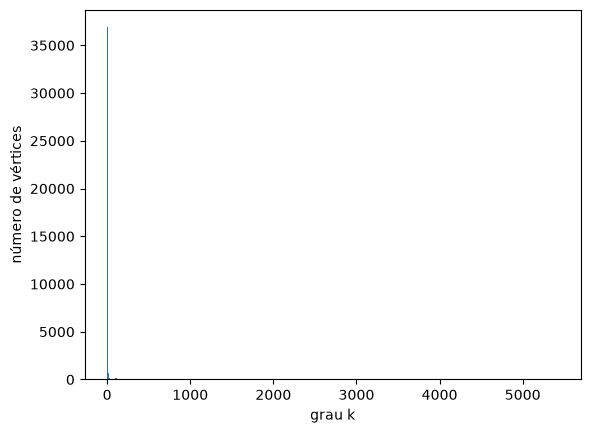

In [18]:
figure, axes = plt.subplots()
axes.bar(degree_distribution["k"], degree_distribution["frequency"], width=1)
axes.set_xlabel("grau k")
axes.set_ylabel("número de vértices")
figure.savefig(FIGURES_DIR / "graus_hist.pdf", bbox_inches="tight", metadata={"CreationDate": None})
plt.show()

### P(k) em escala log-log

Cada ponto é um grau k com a fração P(k) dos vértices que o têm. As duas escalas logarítmicas tornam visível a cauda de graus altos.

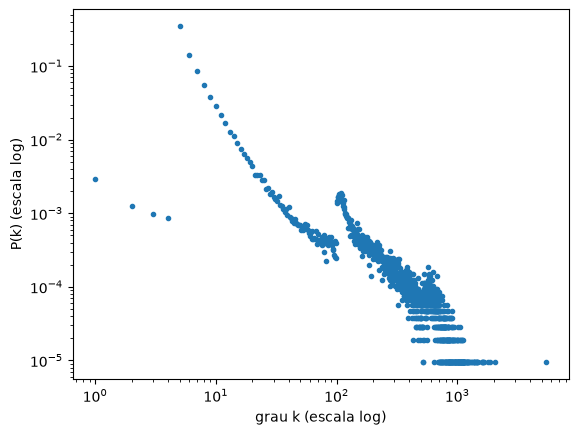

In [19]:
figure, axes = plt.subplots()
axes.loglog(degree_distribution["k"], degree_distribution["p_k"], marker=".", linestyle="none")
axes.set_xlabel("grau k (escala log)")
axes.set_ylabel("P(k) (escala log)")
figure.savefig(FIGURES_DIR / "graus_loglog.pdf", bbox_inches="tight", metadata={"CreationDate": None})
plt.show()

## Clusterização e triângulos

Número de triângulos, coeficiente de clusterização médio e transitividade global do grafo simples completo, lido de `data/processed/`, calculados com o networkx e conferidos com o igraph. Alimenta a subseção Parte I dos resultados do relatório.

In [20]:
import time
from collections.abc import Callable

import igraph as ig
import networkx as nx
import pandas as pd

from src.cache import cached
from src.config import DATA_PROCESSED, TABLES_DIR
from src.io import read_edge_list

### Grafo e medição do tempo

Cada cálculo é cronometrado com `time.perf_counter()` dentro da etapa que passa pelo cache, de modo que o tempo registrado é sempre o da execução que gerou o valor.

In [21]:
def timed[T](compute: Callable[[], T]) -> tuple[T, float]:
    start = time.perf_counter()
    value = compute()
    return value, time.perf_counter() - start


edges = read_edge_list(DATA_PROCESSED / "flickr_simples.edgelist.gz")
graph = nx.Graph(edges)
igraph_graph = ig.Graph(n=graph.number_of_nodes(), edges=edges)

### Triângulos

O networkx conta os triângulos de cada vértice. Como cada triângulo é contado uma vez em cada um dos seus três vértices, o número de triângulos é a soma dividida por 3. O igraph conta diretamente os subgrafos de 3 vértices que formam um triângulo.

In [22]:
triangle_sum, networkx_triangle_time = cached(
    "soma_triangulos_networkx", lambda: timed(lambda: sum(nx.triangles(graph).values()))
)
igraph_triangles, igraph_triangle_time = cached(
    "triangulos_igraph", lambda: timed(lambda: igraph_graph.motifs_randesu(size=3)[3])
)
triangles = triangle_sum // 3

assert triangle_sum % 3 == 0, "a soma dos triângulos por vértice não é múltipla de 3"
assert triangles == igraph_triangles, "networkx e igraph contam triângulos diferentes"

### Clusterização média e transitividade

O coeficiente local de um vértice v de grau k ≥ 2 é 2T(v) / (k(k − 1)), em que T(v) é o número de triângulos de v. Os vértices de grau menor que 2 não têm par de vizinhos e recebem coeficiente 0, e a média é tomada sobre todos os n vértices: é o padrão do networkx e o modo `"zero"` do igraph. A transitividade global é o triplo do número de triângulos dividido pelo número de caminhos de comprimento 2.

In [23]:
average_clustering, networkx_clustering_time = cached(
    "clusterizacao_media_networkx", lambda: timed(lambda: nx.average_clustering(graph))
)
igraph_average_clustering, igraph_clustering_time = cached(
    "clusterizacao_media_igraph",
    lambda: timed(lambda: igraph_graph.transitivity_avglocal_undirected(mode="zero")),
)
transitivity, networkx_transitivity_time = cached(
    "transitividade_networkx", lambda: timed(lambda: nx.transitivity(graph))
)
igraph_transitivity, igraph_transitivity_time = cached(
    "transitividade_igraph", lambda: timed(igraph_graph.transitivity_undirected)
)

assert abs(average_clustering - igraph_average_clustering) < 1e-9, "networkx e igraph divergem na clusterização média"
assert abs(transitivity - igraph_transitivity) < 1e-9, "networkx e igraph divergem na transitividade"

### Tabela

Cada medida aparece com o valor, igual nas duas bibliotecas, e com o tempo do cálculo em cada uma.

In [24]:
time_columns = ["Tempo networkx (s)", "Tempo igraph (s)"]
clustering_table = pd.DataFrame(
    {
        "Valor": [triangles, average_clustering, transitivity],
        time_columns[0]: [networkx_triangle_time, networkx_clustering_time, networkx_transitivity_time],
        time_columns[1]: [igraph_triangle_time, igraph_clustering_time, igraph_transitivity_time],
    },
    index=["Triângulos", "Coeficiente de clusterização médio", "Transitividade global"],
    dtype=object,
)
clustering_table.style.format(thousands=".", decimal=",", precision=6, subset="Valor").format(
    thousands=".", decimal=",", precision=1, subset=time_columns
).to_latex(TABLES_DIR / "clusterizacao.tex", hrules=True, column_format="lrrr")
clustering_table

,Valor,Tempo networkx (s),Tempo igraph (s)
Triângulos,107987357,21.324659,411.668698
Coeficiente de clusterização médio,0.089128,156.978844,0.993745
Transitividade global,0.4016,156.648707,0.844436


## Diâmetro, raio e comprimento médio dos caminhos

Diâmetro, raio e comprimento médio dos caminhos da maior componente, lida de `data/processed/`, calculados de forma exata com uma BFS a partir de cada vértice no igraph. Alimenta a subseção Parte I dos resultados e a Metodologia do relatório.

In [25]:
import time

import igraph as ig
import numpy as np
import pandas as pd

from src.cache import cached
from src.config import DATA_PROCESSED, TABLES_DIR
from src.distancias import compute_eccentricities_and_distance_sums
from src.io import read_edge_list

### Excentricidades e somas das distâncias

Uma BFS a partir de cada vértice dá a excentricidade dele, a maior distância até outro vértice, e a soma das distâncias até todos os demais. As fontes são processadas em lotes de 500 para que a matriz de distâncias nunca fique inteira na memória. O cálculo é cronometrado com `time.perf_counter()` dentro da etapa que passa pelo cache.

In [26]:
def compute_timed_distances() -> tuple[tuple[np.ndarray, np.ndarray], float]:
    start = time.perf_counter()
    distances = compute_eccentricities_and_distance_sums(largest_component)
    return distances, time.perf_counter() - start


largest_component = ig.Graph(edges=read_edge_list(DATA_PROCESSED / "flickr_lcc.edgelist.gz"))
n = largest_component.vcount()
(eccentricities, distance_sums), distance_time = cached(
    "excentricidades_somas_distancias_lcc", compute_timed_distances
)

### Diâmetro, raio e comprimento médio

O diâmetro é a maior excentricidade, o raio é a menor, e o comprimento médio é a soma de todas as distâncias dividida pelo número de pares ordenados, n(n − 1). Como d(u, w) ≤ d(u, v) + d(v, w), o raio fica entre metade do diâmetro e o diâmetro.

In [27]:
diameter = int(eccentricities.max())
radius = int(eccentricities.min())
average_path_length = distance_sums.sum() / (n * (n - 1))

assert diameter / 2 <= radius <= diameter, "o raio não está entre metade do diâmetro e o diâmetro"

### Tabela

Cada medida aparece com o valor exato. A última linha é o tempo da passagem única de BFS que produz as três.

In [28]:
distance_table = pd.DataFrame(
    {"Valor": [diameter, radius, average_path_length, distance_time]},
    index=["Diâmetro", "Raio", "Comprimento médio dos caminhos", "Tempo das BFS (s)"],
    dtype=object,
)
distance_table.style.format(thousands=".", decimal=",", precision=4).to_latex(
    TABLES_DIR / "distancias.tex", hrules=True, column_format="lr"
)
distance_table

,Valor
Diâmetro,9
Raio,5
Comprimento médio dos caminhos,4.33455
Tempo das BFS (s),2580.320543


## Visualização e cobertura da Parte I

Uma visualização de uma amostra da maior componente, lida de `data/processed/`, e a tabela que indica, para cada medida da Parte I, se ela foi calculada e de que forma. Alimenta a subseção Parte I dos resultados do relatório.

In [29]:
import igraph as ig
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from src.config import SEED, DATA_PROCESSED, FIGURES_DIR, TABLES_DIR
from src.io import read_edge_list

### Amostra por bola BFS

O grafo inteiro tem dezenas de milhares de vértices e não cabe num desenho legível. Um vértice da maior componente é sorteado com a semente `SEED`, e a amostra é o subgrafo induzido pelos 300 primeiros vértices alcançados por uma BFS a partir dele.

In [30]:
largest_component = ig.Graph(edges=read_edge_list(DATA_PROCESSED / "flickr_lcc.edgelist.gz"))
center_vertex = int(np.random.default_rng(SEED).integers(largest_component.vcount()))
bfs_order, _, _ = largest_component.bfs(center_vertex)
sample_vertices = bfs_order[:300]
sample = nx.Graph(largest_component.induced_subgraph(sample_vertices).get_edgelist())
pd.Series({"vértices": sample.number_of_nodes(), "arestas": sample.number_of_edges()})

vértices    300
arestas     490
dtype: int64

### Desenho

O tamanho de cada vértice é proporcional ao seu grau na maior componente, e o vértice de partida da BFS fica em vermelho. O número de vértices e de arestas da amostra fica escrito na figura.

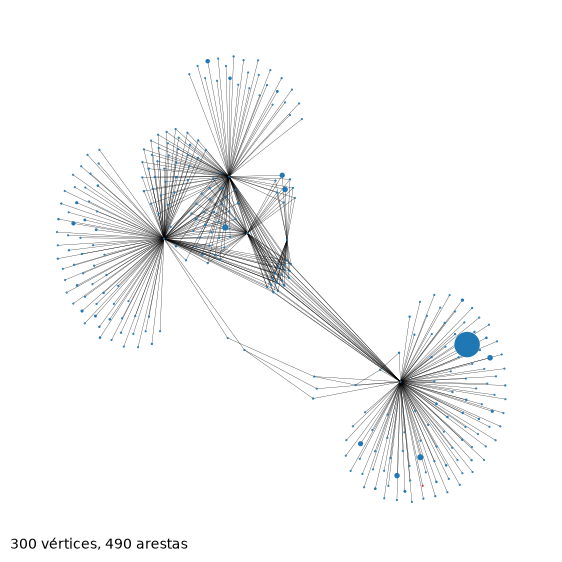

In [31]:
sample_degrees = np.array(largest_component.degree(sample_vertices))
vertex_colors = ["tab:red" if v == 0 else "tab:blue" for v in sample]

figure, axes = plt.subplots(figsize=(7, 7))
nx.draw_networkx(
    sample, nx.spring_layout(sample, seed=SEED), ax=axes, node_color=vertex_colors,
    node_size=[300 * sample_degrees[v] / sample_degrees.max() for v in sample], width=0.2, with_labels=False,
)
axes.text(0, 0, f"{sample.number_of_nodes()} vértices, {sample.number_of_edges()} arestas", transform=axes.transAxes)
axes.set_axis_off()
figure.savefig(FIGURES_DIR / "visualizacao.pdf", bbox_inches="tight", metadata={"CreationDate": None})
plt.show()

### Tabela de cobertura

Cada medida da Parte I do enunciado, com o grafo sobre o qual foi calculada e a forma do cálculo. Todas foram calculadas.

In [32]:
coverage_table = pd.DataFrame(
    [
        ("Número de vértices", "Sim", "Exata", "Completo"),
        ("Número de arestas", "Sim", "Exata", "Completo"),
        ("Grau mínimo, máximo e médio", "Sim", "Exata", "Completo"),
        ("Distribuição de graus", "Sim", "Exata", "Completo"),
        ("Densidade", "Sim", "Exata", "Completo"),
        ("Número de componentes conexas", "Sim", "Exata", "Completo"),
        ("Tamanho de cada componente", "Sim", "Exata", "Completo"),
        ("Diâmetro", "Sim", "Exata", "Maior componente"),
        ("Raio", "Sim", "Exata", "Maior componente"),
        ("Comprimento médio dos caminhos", "Sim", "Exata", "Maior componente"),
        ("Coeficiente de clusterização médio", "Sim", "Exata", "Completo"),
        ("Número de triângulos", "Sim", "Exata", "Completo"),
        ("Visualização", "Sim", "Amostra", "Maior componente"),
    ],
    columns=["Medida", "Calculada", "Forma", "Grafo"],
)
coverage_table.style.hide(axis="index").to_latex(TABLES_DIR / "cobertura_parte1.tex", hrules=True)
coverage_table

,Medida,Calculada,Forma,Grafo
0,Número de vértices,Sim,Exata,Completo
1,Número de arestas,Sim,Exata,Completo
2,"Grau mínimo, máximo e médio",Sim,Exata,Completo
3,Distribuição de graus,Sim,Exata,Completo
4,Densidade,Sim,Exata,Completo
5,Número de componentes conexas,Sim,Exata,Completo
6,Tamanho de cada componente,Sim,Exata,Completo
7,Diâmetro,Sim,Exata,Maior componente
8,Raio,Sim,Exata,Maior componente
9,Comprimento médio dos caminhos,Sim,Exata,Maior componente


## Medição de tempo

Confere a função de `src/benchmark.py` que mede os tempos de execução dos algoritmos da Parte II, descrita na subseção Medição de tempo da Metodologia do relatório. Não usa o grafo.

In [33]:
import pandas as pd

from src.benchmark import measure_time, summarize_times

### Conferência com valores conhecidos

Dois conjuntos de tempos com média, desvio e intervalo calculáveis à mão: 1 a 5 (R = 5, t de Student com 4 graus de liberdade, valor crítico tabelado 2,7764) e 1 a 30 (R = 30, normal, valor crítico tabelado 1,9600). Os limites obtidos são comparados com os calculados a partir das tabelas das duas distribuições.

In [34]:
t_record = summarize_times("conferência", "1 a 5", [1, 2, 3, 4, 5])
z_record = summarize_times("conferência", "1 a 30", list(range(1, 31)))

assert t_record["distribution"] == "t" and z_record["distribution"] == "Z", "a distribuição do IC não segue R"
assert abs(t_record["ci_lower"] - 1.0368) < 1e-3 and abs(t_record["ci_upper"] - 4.9632) < 1e-3, "o IC t de Student difere do calculado à mão"
assert abs(z_record["ci_lower"] - 12.3498) < 1e-3 and abs(z_record["ci_upper"] - 18.6502) < 1e-3, "o IC normal difere do calculado à mão"
pd.DataFrame([t_record, z_record])

,algorithm,input,repetitions,mean,deviation,ci_lower,ci_upper,distribution
0,conferência,1 a 5,5,3.0,1.581139,1.036757,4.963243,t
1,conferência,1 a 30,30,15.5,8.803408,12.349799,18.650201,Z


### Registro de uma medição

A soma dos inteiros de 0 a 10⁶ − 1, executada 30 vezes depois de uma execução de aquecimento descartada, mostra o registro que cada medição devolve.

In [35]:
pd.Series(measure_time("soma", "10^6 inteiros", lambda: sum(range(10**6)), 30))

algorithm                soma
input           10^6 inteiros
repetitions                30
mean                  0.01203
deviation            0.000479
ci_lower             0.011858
ci_upper             0.012201
distribution                Z
dtype: object

## BFS e DFS

Busca em largura e busca em profundidade próprias, iterativas e sobre lista de adjacência, de `src/algoritmos/buscas.py`, conferidas com o networkx e cronometradas com `src/benchmark.py`. Usam a maior componente, lida de `data/processed/`, para que toda fonte alcance todos os vértices e cada execução percorra o grafo inteiro. Alimenta a subseção Parte II dos resultados do relatório.

In [36]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from src.algoritmos.buscas import breadth_first_search, build_adjacency, depth_first_search
from src.benchmark import measure_time
from src.cache import cached
from src.config import SEED, DATA_PROCESSED, FIGURES_DIR, TABLES_DIR
from src.io import read_edge_list

In [37]:
REPETITIONS = 30
SUBGRAPH_FRACTIONS = [0.2, 0.4, 0.6, 0.8, 1.0]

### Validação contra o networkx

Em 5 fontes sorteadas com a semente `SEED`, a BFS própria deve dar as mesmas distâncias que o networkx, e a DFS própria deve alcançar o mesmo conjunto de vértices que a DFS do networkx.

In [38]:
edges = read_edge_list(DATA_PROCESSED / "flickr_lcc.edgelist.gz")
graph = nx.Graph(edges)
n = graph.number_of_nodes()
adjacency = build_adjacency(n, edges)
rng = np.random.default_rng(SEED)

for source in rng.choice(n, size=5, replace=False).tolist():
    distances = breadth_first_search(adjacency, source)
    assert dict(enumerate(distances)) == nx.single_source_shortest_path_length(graph, source), "a BFS própria difere do networkx nas distâncias"
    assert set(depth_first_search(adjacency, source)) == set(nx.dfs_preorder_nodes(graph, source)), "a DFS própria alcança vértices diferentes do networkx"

### Subgrafos de tamanhos crescentes

Cada subgrafo é induzido pelos primeiros vértices da ordem de visita da DFS própria a partir de uma fonte sorteada, numa fração crescente de n. Como todo vértice dessa ordem tem um vizinho visitado antes dele, cada subgrafo é conexo, e a fração 1 é a maior componente inteira.

In [39]:
visit_order = np.array(depth_first_search(adjacency, int(rng.integers(n))))
edge_array = np.array(edges)
subgraphs = []
for fraction in SUBGRAPH_FRACTIONS:
    k = round(fraction * n)
    position = np.full(n, -1)
    position[visit_order[:k]] = np.arange(k)
    subgraph_edges = position[edge_array]
    subgraph_edges = subgraph_edges[(subgraph_edges >= 0).all(axis=1)].tolist()
    subgraphs.append((k, subgraph_edges))
pd.DataFrame([(k, len(subgraph_edges)) for k, subgraph_edges in subgraphs], columns=["vértices", "arestas"])

,vértices,arestas
0,21144,449891
1,42289,732165
2,63433,1624783
3,84578,2203722
4,105722,2316668


### Medição dos tempos

Cada algoritmo é executado em cada subgrafo R = 30 vezes, depois de uma execução de aquecimento, cada vez a partir de uma fonte sorteada com a semente `SEED`. A medição passa pelo cache, de modo que os tempos registrados são os da execução que os gerou.

In [40]:
def measure_searches() -> list[dict]:
    records = []
    for k, subgraph_edges in subgraphs:
        subgraph_adjacency = build_adjacency(k, subgraph_edges)
        for name, search in [("BFS", breadth_first_search), ("DFS", depth_first_search)]:
            sources = iter(rng.integers(k, size=REPETITIONS + 1).tolist())
            record = measure_time(name, f"{k} vértices", lambda: search(subgraph_adjacency, next(sources)), REPETITIONS)
            records.append(record | {"n": k, "m": len(subgraph_edges)})
    return records


times = pd.DataFrame(cached("tempos_buscas_lcc", measure_searches))

### Tabela e figura

A tabela traz, para cada algoritmo e subgrafo, a média, o desvio padrão e o IC de 95% do tempo. Na figura, o tempo médio é posto contra n + m, com o IC como barra de erro: a complexidade O(n + m) prevê pontos alinhados numa reta.

In [41]:
columns = {
    "algorithm": "Algoritmo", "n": "$n$", "m": "$m$", "repetitions": "$R$",
    "mean": "Média (s)", "deviation": "Desvio (s)", "ci_lower": "IC inf. (s)",
    "ci_upper": "IC sup. (s)", "distribution": "Distribuição",
}
times_table = times[list(columns)].rename(columns=columns)
times_table.style.format(thousands=".", decimal=",", precision=4).hide(axis="index").to_latex(
    TABLES_DIR / "tempos_buscas.tex", hrules=True
)
times_table

,Algoritmo,$n$,$m$,$R$,Média (s),Desvio (s),IC inf. (s),IC sup. (s),Distribuição
0,BFS,21144,449891,30,0.037579,0.001741,0.036956,0.038202,Z
1,DFS,21144,449891,30,0.083986,0.002773,0.082993,0.084978,Z
2,BFS,42289,732165,30,0.072110,0.006534,0.069771,0.074448,Z
3,DFS,42289,732165,30,0.165636,0.014457,0.160463,0.170809,Z
4,BFS,63433,1624783,30,0.136480,0.014775,0.131193,0.141767,Z
5,DFS,63433,1624783,30,0.308490,0.029149,0.298059,0.318921,Z
6,BFS,84578,2203722,30,0.188976,0.029074,0.178572,0.199380,Z
7,DFS,84578,2203722,30,0.453534,0.061377,0.431571,0.475498,Z
8,BFS,105722,2316668,30,0.205320,0.009496,0.201922,0.208718,Z
9,DFS,105722,2316668,30,0.439715,0.006285,0.437466,0.441964,Z


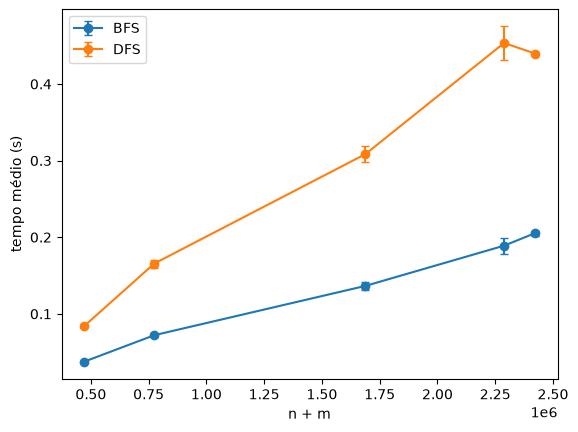

In [42]:
figure, axes = plt.subplots()
for name, algorithm_times in times.groupby("algorithm"):
    axes.errorbar(
        algorithm_times["n"] + algorithm_times["m"], algorithm_times["mean"],
        yerr=algorithm_times["ci_upper"] - algorithm_times["mean"], marker="o", capsize=3, label=name,
    )
axes.set_xlabel("n + m")
axes.set_ylabel("tempo médio (s)")
axes.legend()
figure.savefig(FIGURES_DIR / "tempos_buscas.pdf", bbox_inches="tight", metadata={"CreationDate": None})
plt.show()

## Eulerianidade e Tarjan

Verificação de Eulerianidade pelo teorema de Euler, de `src/algoritmos/euler.py`, e algoritmo de Tarjan iterativo para pontos de articulação e pontes, de `src/algoritmos/tarjan.py`, conferidos com o networkx e cronometrados com `src/benchmark.py`. Usam o grafo simples, que tem mais de uma componente, e subgrafos conexos crescentes da maior componente, ambos lidos de `data/processed/`. Alimenta a subseção Parte II dos resultados do relatório.

In [43]:
import networkx as nx
import numpy as np
import pandas as pd

from src.algoritmos.buscas import build_adjacency, depth_first_search
from src.algoritmos.euler import check_eulerian
from src.algoritmos.tarjan import find_articulation_points_and_bridges
from src.benchmark import measure_time
from src.cache import cached
from src.config import SEED, DATA_PROCESSED, TABLES_DIR
from src.io import read_edge_list

In [44]:
REPETITIONS = 30
SUBGRAPH_FRACTIONS = [0.2, 0.4, 0.6, 0.8, 1.0]

### Validação contra o networkx

No grafo simples, a verificação própria deve concordar com `nx.is_eulerian`, e os conjuntos de articulações e de pontes do Tarjan próprio devem coincidir com os de `nx.articulation_points` e `nx.bridges`.

In [45]:
simple_edges = read_edge_list(DATA_PROCESSED / "flickr_simples.edgelist.gz")
simple_graph = nx.Graph(simple_edges)
simple_adjacency = build_adjacency(simple_graph.number_of_nodes(), simple_edges)
articulation_points, bridges = find_articulation_points_and_bridges(simple_adjacency)

assert check_eulerian(simple_adjacency)["has_eulerian_circuit"] == nx.is_eulerian(simple_graph), "a verificação de circuito euleriano difere do networkx"
assert articulation_points == set(nx.articulation_points(simple_graph)), "as articulações diferem das do networkx"
assert bridges == {(min(u, v), max(u, v)) for u, v in nx.bridges(simple_graph)}, "as pontes diferem das do networkx"

### Subgrafos de tamanhos crescentes

Como na medição da BFS e da DFS, cada subgrafo é induzido pelos primeiros vértices da ordem de visita da DFS própria na maior componente, a partir de uma fonte sorteada, numa fração crescente de n. Cada subgrafo é conexo, e a fração 1 é a maior componente inteira. O grafo simples entra como uma entrada a mais.

In [46]:
lcc_edges = read_edge_list(DATA_PROCESSED / "flickr_lcc.edgelist.gz")
lcc_adjacency = build_adjacency(max(map(max, lcc_edges)) + 1, lcc_edges)
n = len(lcc_adjacency)
rng = np.random.default_rng(SEED)
visit_order = np.array(depth_first_search(lcc_adjacency, int(rng.integers(n))))
edge_array = np.array(lcc_edges)
inputs = [("grafo simples", len(simple_adjacency), simple_edges)]
for fraction in SUBGRAPH_FRACTIONS:
    k = round(fraction * n)
    position = np.full(n, -1)
    position[visit_order[:k]] = np.arange(k)
    subgraph_edges = position[edge_array]
    inputs.append((f"{fraction:.0%} da maior comp.", k, subgraph_edges[(subgraph_edges >= 0).all(axis=1)].tolist()))

### Medição dos tempos e resultados

Cada algoritmo é executado em cada entrada R = 30 vezes, depois de uma execução de aquecimento, e o resultado da execução é gravado junto com o tempo. A medição passa pelo cache.

In [47]:
def measure_euler_tarjan() -> list[dict]:
    records = []
    for entry, k, edges in inputs:
        adjacency = build_adjacency(k, edges)
        eulerian = check_eulerian(adjacency)
        record = measure_time("Eulerianidade", entry, lambda: check_eulerian(adjacency), REPETITIONS)
        records.append(record | {
            "n": k, "m": len(edges), "odd_degree_vertices": eulerian["odd_degree_vertices"],
            "is_connected": "sim" if eulerian["is_connected"] else "não",
        })
        cut_vertices, cut_edges = find_articulation_points_and_bridges(adjacency)
        record = measure_time("Tarjan", entry, lambda: find_articulation_points_and_bridges(adjacency), REPETITIONS)
        records.append(record | {
            "n": k, "m": len(edges), "articulation_points": len(cut_vertices), "bridges": len(cut_edges),
        })
    return records


times = pd.DataFrame(cached("tempos_euler_tarjan", measure_euler_tarjan))

### Tabela

Para cada algoritmo e entrada, o resultado (vértices de grau ímpar e conexidade na Eulerianidade, articulações e pontes no Tarjan), a média, o desvio padrão e o IC de 95% do tempo. A complexidade O(n + m) prevê tempo proporcional a n + m.

In [48]:
columns = {
    "algorithm": "Algoritmo", "input": "Entrada", "n": "$n$", "m": "$m$",
    "odd_degree_vertices": "Grau ímpar", "is_connected": "Conexo",
    "articulation_points": "Articulações", "bridges": "Pontes", "repetitions": "$R$",
    "mean": "Média (s)", "deviation": "Desvio (s)", "ci_lower": "IC inf. (s)", "ci_upper": "IC sup. (s)",
    "distribution": "Distribuição",
}
counts = ["Grau ímpar", "Articulações", "Pontes"]
times_table = times[list(columns)].rename(columns=columns)
times_table["Entrada"] = times_table["Entrada"].str.replace("%", r"\%")
times_table.style.format(thousands=".", decimal=",", precision=4, na_rep="--").format(
    subset=counts, thousands=".", precision=0, na_rep="--"
).hide(axis="index").to_latex(TABLES_DIR / "tempos_euler_tarjan.tex", hrules=True)
times_table

,Algoritmo,Entrada,$n$,$m$,Grau ímpar,Conexo,Articulações,Pontes,$R$,Média (s),Desvio (s),IC inf. (s),IC sup. (s),Distribuição
0,Eulerianidade,grafo simples,105938,2316948,66718.0,não,NaN,NaN,30,0.452396,0.013503,0.447564,0.457228,Z
1,Tarjan,grafo simples,105938,2316948,NaN,NaN,194.0,257.0,30,1.010576,0.286722,0.907975,1.113176,Z
2,Eulerianidade,20\% da maior comp.,21144,289606,10454.0,sim,NaN,NaN,30,0.046417,0.001162,0.046001,0.046833,Z
3,Tarjan,20\% da maior comp.,21144,289606,NaN,NaN,7.0,7.0,30,0.110057,0.002008,0.109338,0.110776,Z
4,Eulerianidade,40\% da maior comp.,42289,1057034,21672.0,sim,NaN,NaN,30,0.183130,0.008730,0.180006,0.186254,Z
5,Tarjan,40\% da maior comp.,42289,1057034,NaN,NaN,37.0,36.0,30,0.402354,0.008580,0.399284,0.405424,Z
6,Eulerianidade,60\% da maior comp.,63433,1478383,34132.0,sim,NaN,NaN,30,0.264281,0.005600,0.262277,0.266285,Z
7,Tarjan,60\% da maior comp.,63433,1478383,NaN,NaN,40.0,38.0,30,0.673273,0.336578,0.552832,0.793714,Z
8,Eulerianidade,80\% da maior comp.,84578,2204337,48202.0,sim,NaN,NaN,30,0.401855,0.015473,0.396318,0.407392,Z
9,Tarjan,80\% da maior comp.,84578,2204337,NaN,NaN,105.0,104.0,30,0.942486,0.274927,0.844106,1.040866,Z


## Dijkstra e Bellman-Ford

Dijkstra com heap binário e Bellman-Ford com parada antecipada, próprios, de `src/algoritmos/caminhos.py`, conferidos com a BFS própria e com o networkx e cronometrados com `src/benchmark.py`. Usam a maior componente, lida de `data/processed/`, para que toda fonte alcance todos os vértices, e subgrafos conexos crescentes dela. Alimenta a subseção Parte II dos resultados do relatório.

In [49]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from src.algoritmos.buscas import breadth_first_search, build_adjacency, depth_first_search
from src.algoritmos.caminhos import bellman_ford, build_weighted_adjacency, dijkstra
from src.benchmark import measure_time
from src.cache import cached
from src.config import SEED, DATA_PROCESSED, FIGURES_DIR, TABLES_DIR
from src.io import read_edge_list

In [50]:
REPETITIONS = 30
SUBGRAPH_FRACTIONS = [0.2, 0.4, 0.6, 0.8, 1.0]

### Política de pesos

O grafo não tem pesos. Com pesos unitários, o Dijkstra deve dar as mesmas distâncias que a BFS própria, conferidas em 5 fontes sorteadas. Para exercitar os algoritmos de fato, cada aresta da maior componente recebe um peso inteiro sorteado em [1, 10], na ordem do arquivo, no primeiro sorteio do gerador criado com a semente `SEED`.

In [51]:
edges = read_edge_list(DATA_PROCESSED / "flickr_lcc.edgelist.gz")
n = max(map(max, edges)) + 1
rng = np.random.default_rng(SEED)
weights = rng.integers(1, 11, size=len(edges))
adjacency = build_adjacency(n, edges)
unit_adjacency = build_weighted_adjacency(n, [(u, v, 1) for u, v in edges])

for source in rng.choice(n, size=5, replace=False).tolist():
    assert dijkstra(unit_adjacency, source) == breadth_first_search(adjacency, source), "com pesos unitários, o Dijkstra difere da BFS"

### Subgrafos de tamanhos crescentes

Como na medição da BFS e da DFS, cada subgrafo é induzido pelos primeiros vértices da ordem de visita da DFS própria a partir de uma fonte sorteada, numa fração crescente de n. Cada subgrafo é conexo, a fração 1 é a maior componente inteira, e cada aresta mantém o peso sorteado na maior componente.

In [52]:
visit_order = np.array(depth_first_search(adjacency, int(rng.integers(n))))
edge_array = np.array(edges)
subgraphs = []
for fraction in SUBGRAPH_FRACTIONS:
    k = round(fraction * n)
    position = np.full(n, -1)
    position[visit_order[:k]] = np.arange(k)
    endpoints = position[edge_array]
    is_inside = (endpoints >= 0).all(axis=1)
    subgraphs.append((k, np.column_stack([endpoints[is_inside], weights[is_inside]]).tolist()))

### Validação com pesos aleatórios

Em cada subgrafo, a partir de uma fonte sorteada, o Dijkstra e o Bellman-Ford próprios devem dar as mesmas distâncias entre si e as mesmas de `nx.single_source_dijkstra_path_length`.

In [53]:
for k, subgraph_edges in subgraphs:
    subgraph_adjacency = build_weighted_adjacency(k, subgraph_edges)
    graph = nx.Graph()
    graph.add_weighted_edges_from(subgraph_edges)
    source = int(rng.integers(k))
    distances = dijkstra(subgraph_adjacency, source)
    assert distances == bellman_ford(subgraph_adjacency, source)[0], "o Dijkstra e o Bellman-Ford dão distâncias diferentes"
    assert dict(enumerate(distances)) == nx.single_source_dijkstra_path_length(graph, source), "o Dijkstra difere do networkx"

### Medição dos tempos

Cada algoritmo é executado em cada subgrafo R = 30 vezes, depois de uma execução de aquecimento, cada vez a partir de uma fonte sorteada com a semente `SEED`. Do Bellman-Ford, registra-se também a média das rodadas até a parada antecipada nas execuções medidas. A medição passa pelo cache.

In [54]:
def measure_shortest_paths() -> list[dict]:
    records = []
    for k, subgraph_edges in subgraphs:
        subgraph_adjacency = build_weighted_adjacency(k, subgraph_edges)
        sources = iter(rng.integers(k, size=REPETITIONS + 1).tolist())
        record = measure_time("Dijkstra", f"{k} vértices", lambda: dijkstra(subgraph_adjacency, next(sources)), REPETITIONS)
        records.append(record | {"n": k, "m": len(subgraph_edges)})
        sources = iter(rng.integers(k, size=REPETITIONS + 1).tolist())
        rounds = []
        record = measure_time(
            "Bellman-Ford", f"{k} vértices",
            lambda: rounds.append(bellman_ford(subgraph_adjacency, next(sources))[1]), REPETITIONS,
        )
        records.append(record | {"n": k, "m": len(subgraph_edges), "rounds": np.mean(rounds[1:])})
    return records


times = pd.DataFrame(cached("tempos_caminhos", measure_shortest_paths))

### Tabela e figura

A tabela traz, para cada algoritmo e subgrafo, a média, o desvio padrão e o IC de 95% do tempo e, no Bellman-Ford, a média das rodadas e a estimativa do tempo sem parada antecipada: as n − 1 rodadas ao custo médio de uma rodada, isto é, a média do tempo dividida pela média das rodadas. Na figura, o tempo médio de cada algoritmo é posto contra o custo que a sua complexidade teórica prevê, (n + m) log n no Dijkstra e nm no Bellman-Ford, com o IC como barra de erro.

In [55]:
times["hours_without_early_stop"] = (times["n"] - 1) * times["mean"] / times["rounds"] / 3600
columns = {
    "algorithm": "Algoritmo", "n": "$n$", "m": "$m$", "repetitions": "$R$", "rounds": "Rodadas",
    "mean": "Média (s)", "deviation": "Desvio (s)", "ci_lower": "IC inf. (s)", "ci_upper": "IC sup. (s)",
    "distribution": "Distribuição", "hours_without_early_stop": "Sem parada (h)",
}
estimates = ["Rodadas", "Sem parada (h)"]
times_table = times[list(columns)].rename(columns=columns)
times_table.style.format(thousands=".", decimal=",", precision=4).format(
    subset=estimates, thousands=".", decimal=",", precision=1, na_rep="--"
).hide(axis="index").to_latex(TABLES_DIR / "tempos_caminhos.tex", hrules=True)
times_table

,Algoritmo,$n$,$m$,$R$,Rodadas,Média (s),Desvio (s),IC inf. (s),IC sup. (s),Distribuição,Sem parada (h)
0,Dijkstra,21144,304921,30,NaN,0.082852,0.002403,0.081992,0.083712,Z,NaN
1,Bellman-Ford,21144,304921,30,9.833333,0.664158,0.076571,0.636758,0.691558,Z,0.396675
2,Dijkstra,42289,878323,30,NaN,0.246131,0.004738,0.244436,0.247827,Z,NaN
3,Bellman-Ford,42289,878323,30,9.333333,1.947783,0.189775,1.879874,2.015692,Z,2.451424
4,Dijkstra,63433,1545315,30,NaN,0.421423,0.009067,0.418179,0.424668,Z,NaN
5,Bellman-Ford,63433,1545315,30,9.166667,3.302790,0.358436,3.174527,3.431052,Z,6.348562
6,Dijkstra,84578,2205088,30,NaN,0.633454,0.010857,0.629569,0.637339,Z,NaN
7,Bellman-Ford,84578,2205088,30,8.833333,4.629931,0.485576,4.456173,4.803689,Z,12.314015
8,Dijkstra,105722,2316668,30,NaN,0.737632,0.010631,0.733828,0.741437,Z,NaN
9,Bellman-Ford,105722,2316668,30,9.100000,5.059205,0.369846,4.926860,5.191550,Z,16.326746


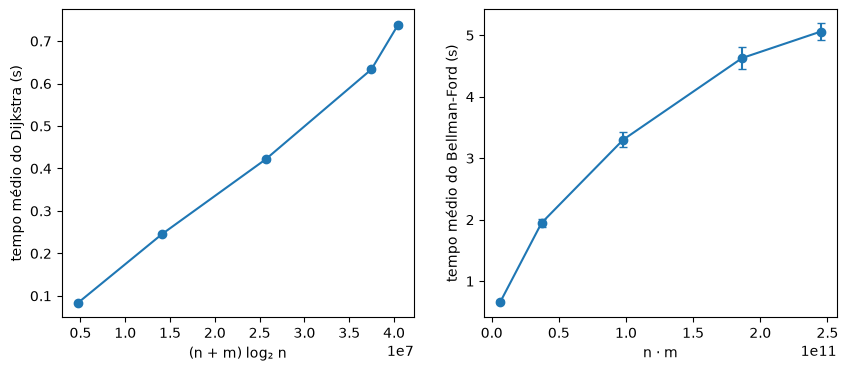

In [56]:
dijkstra_times = times[times["algorithm"] == "Dijkstra"]
bellman_ford_times = times[times["algorithm"] == "Bellman-Ford"]
figure, (dijkstra_axes, bellman_ford_axes) = plt.subplots(1, 2, figsize=(10, 4))
dijkstra_axes.errorbar(
    (dijkstra_times["n"] + dijkstra_times["m"]) * np.log2(dijkstra_times["n"]), dijkstra_times["mean"],
    yerr=dijkstra_times["ci_upper"] - dijkstra_times["mean"], marker="o", capsize=3,
)
dijkstra_axes.set_xlabel("(n + m) log₂ n")
dijkstra_axes.set_ylabel("tempo médio do Dijkstra (s)")
bellman_ford_axes.errorbar(
    bellman_ford_times["n"] * bellman_ford_times["m"], bellman_ford_times["mean"],
    yerr=bellman_ford_times["ci_upper"] - bellman_ford_times["mean"], marker="o", capsize=3,
)
bellman_ford_axes.set_xlabel("n · m")
bellman_ford_axes.set_ylabel("tempo médio do Bellman-Ford (s)")
figure.savefig(FIGURES_DIR / "tempos_caminhos.pdf", bbox_inches="tight", metadata={"CreationDate": None})
plt.show()

## Floyd-Warshall

Floyd-Warshall próprio e vetorizado, de `src/algoritmos/floyd_warshall.py`, conferido com o Dijkstra próprio e cronometrado com `src/benchmark.py`. Usa subgrafos da maior componente, lida de `data/processed/`, amostrados por bolas BFS, com os mesmos pesos aleatórios da seção do Dijkstra e do Bellman-Ford. Alimenta a subseção Parte II dos resultados do relatório.

In [57]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.algoritmos.buscas import breadth_first_search, build_adjacency
from src.algoritmos.caminhos import build_weighted_adjacency, dijkstra
from src.algoritmos.floyd_warshall import floyd_warshall
from src.benchmark import measure_time
from src.cache import cached
from src.config import SEED, DATA_PROCESSED, FIGURES_DIR, TABLES_DIR
from src.io import read_edge_list

In [58]:
REPETITIONS = {250: 30, 500: 30, 1000: 10, 2000: 10}

### Subgrafos por bola BFS

Cada aresta da maior componente recebe o peso inteiro em [1, 10] do primeiro sorteio do gerador criado com a semente `SEED`, como na seção do Dijkstra e do Bellman-Ford. Cada subgrafo é induzido pelos k vértices mais próximos de um centro sorteado, na ordem das distâncias da BFS própria: a bola contém as camadas inteiras até a penúltima, e cada vértice da última tem vizinho na anterior, de modo que o subgrafo é conexo.

In [59]:
edges = read_edge_list(DATA_PROCESSED / "flickr_lcc.edgelist.gz")
n = max(map(max, edges)) + 1
rng = np.random.default_rng(SEED)
weights = rng.integers(1, 11, size=len(edges))
center_distances = breadth_first_search(build_adjacency(n, edges), int(rng.integers(n)))
ball_order = np.argsort(center_distances, kind="stable")
edge_array = np.array(edges)
subgraphs = {}
for k in REPETITIONS:
    position = np.full(n, -1)
    position[ball_order[:k]] = np.arange(k)
    endpoints = position[edge_array]
    is_inside = (endpoints >= 0).all(axis=1)
    subgraphs[k] = np.column_stack([endpoints[is_inside], weights[is_inside]]).tolist()

### Validação

No subgrafo de 250 vértices, a matriz de distâncias do Floyd-Warshall deve coincidir com as distâncias do Dijkstra próprio a partir de cada um dos 250 vértices.

In [60]:
subgraph_adjacency = build_weighted_adjacency(250, subgraphs[250])
dijkstra_distances = [dijkstra(subgraph_adjacency, source) for source in range(250)]
assert np.array_equal(floyd_warshall(250, subgraphs[250]), dijkstra_distances), "o Floyd-Warshall difere do Dijkstra a partir de todas as fontes"

### Medição dos tempos

O algoritmo é executado em cada subgrafo R vezes, depois de uma execução de aquecimento: R = 30 nos subgrafos de 250 e 500 vértices e R = 10 nos de 1000 e 2000, cujas execuções levam segundos. Com R < 30, o IC usa a distribuição t de Student. A medição passa pelo cache.

In [61]:
def measure_floyd_warshall() -> list[dict]:
    records = []
    for k, subgraph_edges in subgraphs.items():
        record = measure_time("Floyd-Warshall", "bola BFS", lambda: floyd_warshall(k, subgraph_edges), REPETITIONS[k])
        records.append(record | {"n": k, "m": len(subgraph_edges)})
    return records


times = pd.DataFrame(cached("tempos_floyd", measure_floyd_warshall))

### Escala log-log

A reta ajustada por mínimos quadrados a log(tempo médio) × log(n) estima o expoente do crescimento observado, comparado com o expoente teórico 3 por uma reta de referência n³ que passa pelo primeiro ponto.

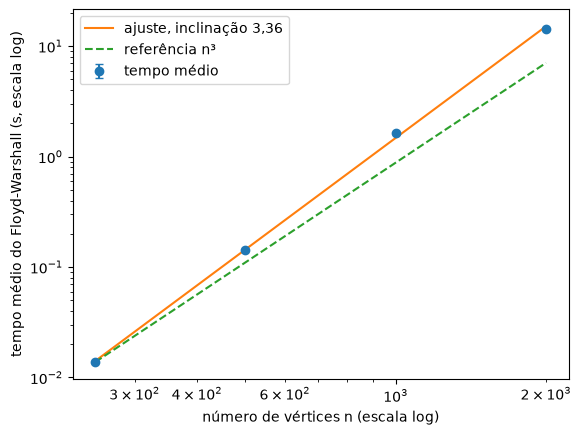

In [62]:
slope, intercept = np.polyfit(np.log(times["n"]), np.log(times["mean"]), 1)
figure, axes = plt.subplots()
axes.errorbar(
    times["n"], times["mean"], yerr=times["ci_upper"] - times["mean"],
    marker="o", capsize=3, linestyle="none", label="tempo médio",
)
axes.plot(times["n"], np.exp(intercept) * times["n"] ** slope, label=f"ajuste, inclinação {slope:.2f}".replace(".", ","))
axes.plot(times["n"], times["mean"][0] * (times["n"] / times["n"][0]) ** 3, linestyle="--", label="referência n³")
axes.set_xscale("log")
axes.set_yscale("log")
axes.set_xlabel("número de vértices n (escala log)")
axes.set_ylabel("tempo médio do Floyd-Warshall (s, escala log)")
axes.legend()
figure.savefig(FIGURES_DIR / "floyd_escala.pdf", bbox_inches="tight", metadata={"CreationDate": None})
plt.show()

### Tabela

A tabela traz, para cada subgrafo, a média, o desvio padrão e o IC de 95% do tempo e a memória da matriz de distâncias, n² números de ponto flutuante de 8 bytes. A última linha é a maior componente inteira, em que o algoritmo não é executado: a memória que a matriz exigiria e o tempo que a reta ajustada extrapola para o seu n.

In [63]:
largest_component = {
    "input": "maior componente", "n": n, "m": len(edges),
    "estimated_days": np.exp(intercept) * n ** slope / 86400,
}
times = pd.concat([times, pd.DataFrame([largest_component])], ignore_index=True)
times["memory_gb"] = times["n"] ** 2 * 8 / 1e9
columns = {
    "input": "Entrada", "n": "$n$", "m": "$m$", "repetitions": "$R$",
    "mean": "Média (s)", "deviation": "Desvio (s)", "ci_lower": "IC inf. (s)", "ci_upper": "IC sup. (s)",
    "distribution": "Distribuição", "memory_gb": "Memória (GB)", "estimated_days": "Estimado (dias)",
}
times_table = times[list(columns)].rename(columns=columns)
times_table.style.format(thousands=".", decimal=",", precision=4, na_rep="--").format(
    subset=["$R$"], precision=0, na_rep="--"
).format(subset=["Estimado (dias)"], thousands=".", decimal=",", precision=1, na_rep="--").hide(axis="index").to_latex(
    TABLES_DIR / "tempos_floyd.tex", hrules=True
)
times_table

,Entrada,$n$,$m$,$R$,Média (s),Desvio (s),IC inf. (s),IC sup. (s),Distribuição,Memória (GB),Estimado (dias)
0,bola BFS,250,340,30.0,0.013769,0.000094,0.013735,0.013803,Z,0.00050,NaN
1,bola BFS,500,704,30.0,0.141858,0.000679,0.141615,0.142101,Z,0.00200,NaN
2,bola BFS,1000,1454,10.0,1.632184,0.008177,1.626334,1.638033,t,0.00800,NaN
3,bola BFS,2000,3336,10.0,14.224752,0.045504,14.192201,14.257304,t,0.03200,NaN
4,maior componente,105722,2316668,NaN,NaN,NaN,NaN,NaN,NaN,89.41713,106.273727


## Árvore geradora mínima (Kruskal)

Kruskal próprio com union-find, de `src/algoritmos/kruskal.py`, conferido com o networkx e cronometrado com `src/benchmark.py`. Usa a maior componente, lida de `data/processed/`, que é conexa e por isso tem árvore geradora, com os mesmos pesos aleatórios da seção do Dijkstra e do Bellman-Ford, e subgrafos conexos crescentes dela. Alimenta a subseção Parte II dos resultados do relatório.

In [64]:
import networkx as nx
import numpy as np
import pandas as pd

from src.algoritmos.buscas import build_adjacency, depth_first_search
from src.algoritmos.kruskal import kruskal
from src.benchmark import measure_time
from src.cache import cached
from src.config import SEED, DATA_PROCESSED, TABLES_DIR
from src.io import read_edge_list

In [65]:
REPETITIONS = 30
SUBGRAPH_FRACTIONS = [0.2, 0.4, 0.6, 0.8, 1.0]

### Validação na maior componente

Cada aresta da maior componente recebe o peso inteiro em [1, 10] do primeiro sorteio do gerador criado com a semente `SEED`, como na seção do Dijkstra e do Bellman-Ford. A árvore do Kruskal próprio deve ter n − 1 arestas, ser acíclica e ter o mesmo peso total que a de `nx.minimum_spanning_tree`.

In [66]:
edges = read_edge_list(DATA_PROCESSED / "flickr_lcc.edgelist.gz")
n = max(map(max, edges)) + 1
rng = np.random.default_rng(SEED)
weights = rng.integers(1, 11, size=len(edges))
weighted_edges = np.column_stack([edges, weights]).tolist()
tree = kruskal(n, weighted_edges)
graph = nx.Graph()
graph.add_weighted_edges_from(weighted_edges)

assert len(tree) == n - 1, "a árvore não tem n − 1 arestas"
assert nx.is_forest(nx.Graph([(u, v) for u, v, _ in tree])), "a árvore tem ciclo"
assert sum(weight for _, _, weight in tree) == nx.minimum_spanning_tree(graph).size(weight="weight"), "o peso da árvore difere do networkx"

### Subgrafos de tamanhos crescentes

Como na seção do Dijkstra e do Bellman-Ford, cada subgrafo é induzido pelos primeiros vértices da ordem de visita da DFS própria a partir de uma fonte sorteada, numa fração crescente de n. Cada subgrafo é conexo, a fração 1 é a maior componente inteira, e cada aresta mantém o peso sorteado na maior componente.

In [67]:
visit_order = np.array(depth_first_search(build_adjacency(n, edges), int(rng.integers(n))))
edge_array = np.array(edges)
subgraphs = []
for fraction in SUBGRAPH_FRACTIONS:
    k = round(fraction * n)
    position = np.full(n, -1)
    position[visit_order[:k]] = np.arange(k)
    endpoints = position[edge_array]
    is_inside = (endpoints >= 0).all(axis=1)
    subgraphs.append((f"{fraction:.0%} da maior comp.", k, np.column_stack([endpoints[is_inside], weights[is_inside]]).tolist()))

### Medição dos tempos

O algoritmo é executado em cada subgrafo R = 30 vezes, depois de uma execução de aquecimento, e o peso da árvore é gravado junto com o tempo. A medição passa pelo cache.

In [68]:
def measure_kruskal() -> list[dict]:
    records = []
    for entry, k, subgraph_edges in subgraphs:
        tree_weight = sum(weight for _, _, weight in kruskal(k, subgraph_edges))
        record = measure_time("Kruskal", entry, lambda: kruskal(k, subgraph_edges), REPETITIONS)
        records.append(record | {"n": k, "m": len(subgraph_edges), "tree_weight": tree_weight})
    return records


times = pd.DataFrame(cached("tempos_agm", measure_kruskal))

### Tabela

Para cada subgrafo, o peso da árvore, a média, o desvio padrão e o IC de 95% do tempo e a média dividida por m log₂ m. A complexidade O(m log m) prevê que essa razão fique aproximadamente constante.

In [69]:
times["ns_per_m_log_m"] = times["mean"] / (times["m"] * np.log2(times["m"])) * 1e9
columns = {
    "input": "Entrada", "n": "$n$", "m": "$m$", "tree_weight": "Peso da AGM", "repetitions": "$R$",
    "mean": "Média (s)", "deviation": "Desvio (s)", "ci_lower": "IC inf. (s)", "ci_upper": "IC sup. (s)",
    "distribution": "Distribuição", "ns_per_m_log_m": "Média / ($m \\log_2 m$) (ns)",
}
times_table = times[list(columns)].rename(columns=columns)
times_table["Entrada"] = times_table["Entrada"].str.replace("%", r"\%")
times_table.style.format(thousands=".", decimal=",", precision=4).format(
    subset=["Média / ($m \\log_2 m$) (ns)"], decimal=",", precision=2
).hide(axis="index").to_latex(TABLES_DIR / "tempos_agm.tex", hrules=True)
times_table

,Entrada,$n$,$m$,Peso da AGM,$R$,Média (s),Desvio (s),IC inf. (s),IC sup. (s),Distribuição,Média / ($m \log_2 m$) (ns)
0,20\% da maior comp.,21144,289747,48297,30,0.142913,0.003414,0.141691,0.144135,Z,27.183732
1,40\% da maior comp.,42289,1080560,82878,30,0.507085,0.011294,0.503044,0.511127,Z,23.413267
2,60\% da maior comp.,63433,1602675,116206,30,0.726132,0.003905,0.724735,0.727530,Z,21.981089
3,80\% da maior comp.,84578,2200932,150805,30,0.994332,0.010154,0.990699,0.997966,Z,21.442077
4,100\% da maior comp.,105722,2316668,193889,30,1.094209,0.045497,1.077928,1.110489,Z,22.338657
